# Day 25 | Keep a Conversation's History

**KGP Talkie**

Store chat turns and keep each session separate.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
import langchain_core
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

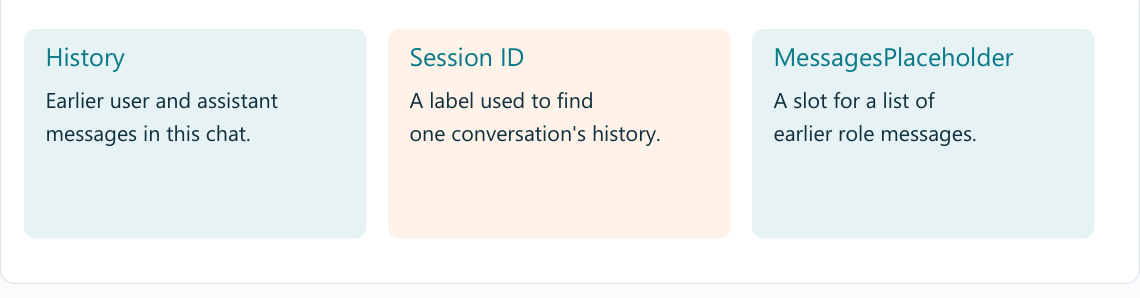

ChatOllama sends chat requests to the local Ollama server.

In [5]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [6]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [7]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

A chat prompt template fills named inputs and keeps message roles.

In [8]:
from langchain_core.prompts import ChatPromptTemplate

In [9]:
from langchain_core.prompts import MessagesPlaceholder
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

This dictionary holds separate histories during this kernel run.

In [10]:
histories = {}

A new ID creates a new history; an existing ID returns that chat's earlier turns.

In [11]:
def get_history(session_id):
    if session_id not in histories:
        histories[session_id] = InMemoryChatMessageHistory()
    return histories[session_id]

In [12]:
prompt = ChatPromptTemplate.from_messages([("system", "Use only the chat facts. If a name was not given, say it is unknown."), MessagesPlaceholder("history"), ("human", "{question}")])

In [13]:
chat = RunnableWithMessageHistory(prompt | llm, get_history, input_messages_key="question", history_messages_key="history")

C:\Users\Acer\Downloads\80 Hour Genai Materials\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3823: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [14]:
session_a = {"configurable": {"session_id": "class-a"}}

In [15]:
print(chat.invoke({"question": "My name is Asha."}, config=session_a).content)

Nice to meet you, Asha! Is there something I can help you with or would you like to chat?


In [16]:
print(chat.invoke({"question": "What is my name?"}, config=session_a).content)

Your name is Asha.


A fresh session does not contain Asha's name. Read its actual output.

In [17]:
print(chat.invoke({"question": "What is my name?"}, config={"configurable": {"session_id": "class-b"}}).content)

I don't have any information about your identity or personal details, including your name. I'm a large language model, I don't retain any data about individual users, and our conversation just started. Would you like to introduce yourself?


Inspect what was stored. These turns will be sent again as input.

In [18]:
[(m.type, m.content) for m in histories["class-a"].messages]

[('human', 'My name is Asha.'),
 ('ai',
  'Nice to meet you, Asha! Is there something I can help you with or would you like to chat?'),
 ('human', 'What is my name?'),
 ('ai', 'Your name is Asha.')]

In [19]:
from langchain_community.chat_message_histories import SQLChatMessageHistory

In [20]:
disk_history = SQLChatMessageHistory(session_id="demo", connection="sqlite:///" + str(OUTPUT / "history.db"))

Clear only our local demo session so rerunning does not duplicate its sample turns.

In [21]:
disk_history.clear()
disk_history.add_user_message("My name is Mia.")

In [22]:
disk_history.messages

[HumanMessage(content='My name is Mia.', additional_kwargs={}, response_metadata={})]

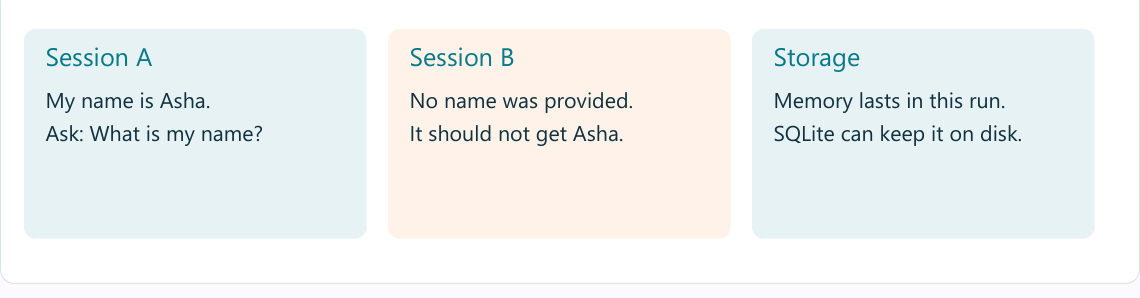

## Try a fresh input

Try a SQLite history store and clear only the classroom session you created.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-chat-memory).